# Аудит A/B-теста и проверка статистической гипотезы

Проект курса «Аналитик данных» (Яндекс Практикум), итоговая работа базового курса.

Две независимые задачи в одном ноутбуке:
- **Часть 1.** Проверка гипотезы о различии времени активности пользователей Яндекс Книг в Москве и Санкт-Петербурге: тест Уэлча и аналитическая записка.
- **Часть 2.** Аудит корректности A/B-теста нового интерфейса интернет-магазина BitMotion Kit и оценка его результатов: Z-тест для конверсии.

### Данные

`yandex_knigi_data.csv` — активность пользователей Яндекс Книг (данные предоставлены Яндекс Практикумом, в репозиторий не включены):
- `city` — город пользователя;
- `puid` — идентификатор пользователя;
- `hours` — количество часов, проведённых пользователем за чтением или прослушиванием книг.

`ab_test_participants.csv` — участники A/B-тестов:
- `user_id` — идентификатор пользователя; `group` — группа теста;
- `ab_test` — название теста; `device` — устройство регистрации.

`ab_test_events` — события пользователей интернет-магазина:
- `event_dt` — дата и время события; `event_name` — тип события;
- `details` — дополнительные данные о событии.

### Структура работы

1. Загрузка и проверка данных на дубликаты.
2. Сравнение групп, распределений и статистический тест.
3. Аналитическая записка с интерпретацией результата.
4. Аудит корректности A/B-теста: чистка выборки, равномерность групп, горизонт анализа, достаточность выборки.
5. Расчёт конверсии в группах и Z-тест для долевой метрики.

## Часть 1. Проверка гипотезы о времени активности пользователей Яндекс Книг

**Цель:** проверить, действительно ли пользователи из Санкт-Петербурга проводят больше времени за чтением и прослушиванием книг, чем пользователи из Москвы.

**Задачи:** проверить датафрейм на повторы, сравнить размеры групп, их статистики и распределение, провести статистический тест и проанализировать результаты.

Средняя активность — среднепользовательская метрика, поэтому проверяем гипотезу о средних с помощью односторонней проверки с двумя выборками:

- H₀: μ_СПб ≤ μ_Москва — среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве;
- H₁: μ_СПб > μ_Москва — среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [14]:
# Импортируем необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
from statsmodels.stats.proportion import proportions_ztest

In [15]:
# Загружаем данные (файл предоставлен Яндекс Практикумом, в репозиторий не входит)
df = pd.read_csv('https://code.s3.yandex.net/datasets/yandex_knigi_data.csv')

# Знакомимся с данными
df.info()

df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   object 
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 274.6+ KB


,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


In [16]:
# Проверим пользователей на дубликаты
df['puid'].duplicated().sum()

np.int64(244)

В таблице присутствует 244 повтора. Уберём все, кроме первого.

In [17]:
df = df.drop_duplicates(subset=['puid'], keep='first')
df['puid'].duplicated().sum()

np.int64(0)

Для выбора теста проверим данные на нормальность: построим гистограммы распределений по группам.

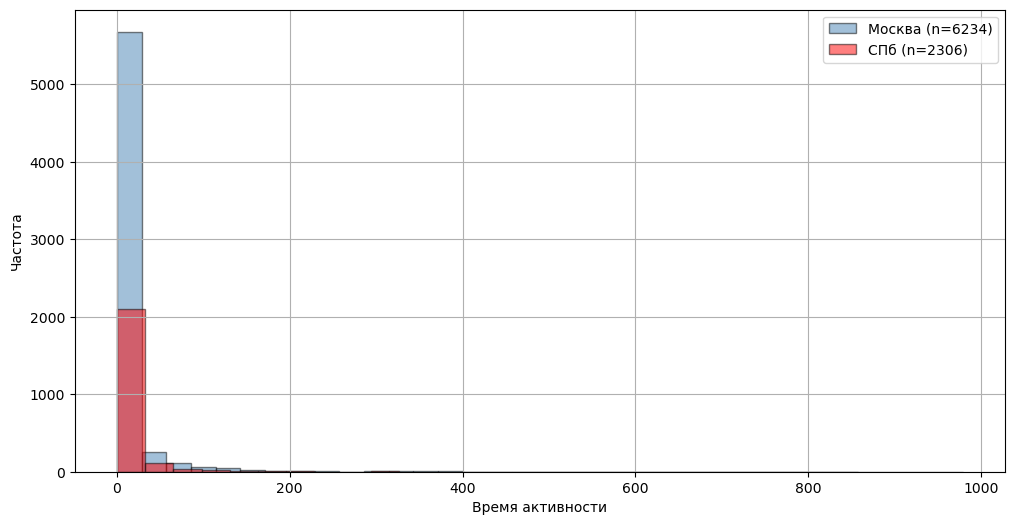

In [18]:
# Разделим данные по городам
moscow_data = df[df['city']=='Москва']['hours']
spb_data = df[df['city']=='Санкт-Петербург']['hours']

# Для проверки нормальности данных построим гистограммы
plt.figure(figsize=(12,6))

plt.hist(moscow_data, bins=30, alpha=0.5, color='steelblue', label=f'Москва (n={len(moscow_data)})', edgecolor='black')
plt.hist(spb_data, bins=30, alpha=0.5, color='red', label=f'СПб (n={len(spb_data)})', edgecolor='black')

plt.xlabel('Время активности')
plt.ylabel('Частота')
plt.legend()
plt.grid()
plt.show()

График показывает, что распределения довольно похожи: сильная концентрация значений у нуля, правый хвост. Поскольку необходимо сравнить средние значения, используем t-тест Уэлча.

In [19]:
# Проведем тест
stat, pvalue = st.ttest_ind(spb_data, moscow_data, alternative='greater')

# Обозначим уровень стат значимости
alpha = 0.05

print(f't-статистика = {stat}, pvalue = {pvalue}')

if pvalue < alpha:
      print('Пользователи из СПб проводят статистически значимо больше времени.')
else:
      print('Нет значимых доказательств, что пользователи СПб проводят больше времени, чем пользователи из Москвы.')

t-статистика = 0.4174122942907679, pvalue = 0.338193679651558
Нет значимых доказательств, что пользователи СПб проводят больше времени, чем пользователи из Москвы.


### Аналитическая записка

В ходе работы мы провели односторонний тест Уэлча с уровнем статистической значимости 5%. Выбор теста обусловлен особенностями выборки: сильная концентрация значений у нуля, схожие распределения и схожие средние; метрика среднепользовательская, поэтому сравниваем именно средние значения.

Результатом теста стала t-статистика, равная примерно 0,4. P-value = 0,3381, или около 34%. Это означает, что если бы на самом деле различий не было, вероятность получить такое же или ещё более экстремальное отличие составила бы 34%. Данные не дают оснований утверждать, что пользователи из Санкт-Петербурга проводят в приложении больше времени, чем пользователи из Москвы.

Возможные причины такого результата:
- смешанность активности: допустимо, что в Москве чаще слушают книги, а в Санкт-Петербурге больше читают; на чтение обычно тратят меньше времени, чем на прослушивание, которое можно совмещать с дорогой и прогулками;
- искажение ранжирования из-за объёмных выбросов: в Москве из-за большего числа пользователей может быть больше людей, которые сотнями часов слушают или читают книги.

## Часть 2. Аудит результатов A/B-теста (интернет-магазин BitMotion Kit)

**Цель:** оценить, приводит ли новая версия интерфейса интернет-магазина BitMotion Kit к статистически значимому увеличению доли пользователей, совершающих покупку, по сравнению со старой версией.

**Задачи:** проверить корректность проведения A/B-теста, рассчитать конверсию в покупку в контрольной и тестовой группах, выполнить статистический тест для проверки значимости различий и интерпретировать результаты с точки зрения бизнес-эффекта.

In [20]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [21]:
participants.head()

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


Сразу обнаруживаем, что пользователям могут соответствовать разные названия тестов и группы. Нам важно оставить только группы A и B теста `interface_eu_test` — остальные тесты не являются предметом нашего рассмотрения.

In [22]:
# Добавим столбец ab_test_group
participants['ab_test_group'] = participants['ab_test'] + '_' + participants['group']

# Сгруппируем данные по столбцу user_id
grouped_users = participants.groupby('user_id')['ab_test_group'].nunique()

# Удалим пользователей, которые имеют больше одной группы или теста
users_to_remove = grouped_users[grouped_users > 1].index
participants = participants[~participants['user_id'].isin(users_to_remove)]

# Отфильтруем пользователей с другим тестом
participants = participants[participants['ab_test'] == 'interface_eu_test']

In [23]:
# Проверим равномерность распределения пользователей
participants_A = len(participants[participants['group'] == 'A'])
participants_B = len(participants[participants['group'] == 'B'])

participants_total = participants_A + participants_B

print(f'Доля пользователей группы А: {round(participants_A/participants_total, 2)}, кол-во: {participants_A}')
print(f'Доля пользователей группы B: {round(participants_B/participants_total, 2)}, кол-во: {participants_B}')

# Проверим пользователей на пересечения
users_A = set(participants[participants['group'] == 'A']['user_id'])
users_B = set(participants[participants['group'] == 'B']['user_id'])

intersection = users_A & users_B

print(len(intersection))

Доля пользователей группы А: 0.5, кол-во: 4952
Доля пользователей группы B: 0.5, кол-во: 5011
0


Группы распределены практически равномерно, пересечений не обнаружено.

In [24]:
events.head()

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


Обнаруживаем, что пользователь может появляться несколько раз, при этом в столбце `details` могут отсутствовать данные. Оставляем только события пользователей, которые представлены в таблице `participants` в тесте `interface_eu_test`.

In [25]:
# Отфильтруем датафрейм, оставив только нужные нам значения
events = events[events['user_id'].isin(participants['user_id'])]

Определим горизонт анализа: оставим только события, выполненные в течение первых семи дней с момента регистрации.

In [26]:
# Рассмотрим горизонт анализа
events_dt_min = events['event_dt'].min()
events_dt_max = events['event_dt'].max()

events_horizon = events_dt_max - events_dt_min

print(f'Горизонт анализа от {events_dt_min} до {events_dt_max} равен {events_horizon}')

# Оставим только события, произошедшие в первые семь дней
# Определим дни регистрации
reg_dates = events[events['event_name'] == 'registration'][['user_id', 'event_dt']]
reg_dates.columns = ['user_id', 'reg_date']

# Присоединим даты регистраций к датафрейму events
events = events.merge(reg_dates, on='user_id')

# Оставляем только первые 7 дней
events = events[
    (events['event_dt'] >= events['reg_date']) &
    (events['event_dt'] <= events['reg_date'] + pd.Timedelta(days=7))]

# Удаляем столбец reg_date
events = events.drop(columns=['reg_date'])
events.count()

Горизонт анализа от 2020-12-06 14:10:01 до 2020-12-30 18:34:08 равен 24 days 04:24:07


user_id       63805
event_dt      63805
event_name    63805
details       16125
dtype: int64

Оценим достаточность выборки для получения статистически значимых результатов. Заданные параметры: базовый показатель конверсии — 30%, мощность теста — 80%, достоверность — 95%.

In [27]:
# Минимальный размер выборки рассчитан с помощью калькулятора Эвана Миллера
sample_size = 3692
total_size = sample_size * 2

# Количество пользователей в тесте
users_count = events['user_id'].nunique()

if total_size < users_count:
    print(f'Рекомендуемый размер выборки: {total_size}, в нашем тесте размер оказался {users_count}, т.е. достаточен')
else:
    print(f'Рекомендуемый размер выборки: {total_size}, в нашем тесте размер оказался {users_count}, т.е. недостаточен')

Рекомендуемый размер выборки: 7384, в нашем тесте размер оказался 9963, т.е. достаточен


Рассчитаем для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [28]:
# Объединим датафреймы, добавим информацию о группах в events
events = events.merge(participants[['user_id', 'group']], on='user_id', how='left')

# Рассчитаем статистики для группы А
visitors_a = events[events['group'] == 'A']['user_id'].nunique()
buyers_a = events[(events['group'] == 'A') & (events['event_name'] == 'purchase')]['user_id'].nunique()
buyers_share_a = buyers_a / visitors_a

# Рассчитаем статистики для группы B
visitors_b = events[events['group'] == 'B']['user_id'].nunique()
buyers_b = events[(events['group'] == 'B') & (events['event_name'] == 'purchase')]['user_id'].nunique()
buyers_share_b = buyers_b / visitors_b

print(f'Количество посетителей в контрольной группе: {visitors_a}, '
      f'Количество покупателей в контрольной группе: {buyers_a}, '
      f'Доля покупателей в контрольной группе: {round(buyers_share_a, 4)}')

print(f'Количество посетителей в тестовой группе: {visitors_b}, '
      f'Количество покупателей в тестовой группе: {buyers_b}, '
      f'Доля покупателей в тестовой группе: {round(buyers_share_b, 4)}')

Количество посетителей в контрольной группе: 4952, Количество покупателей в контрольной группе: 1377, Доля покупателей в контрольной группе: 0.2781
Количество посетителей в тестовой группе: 5011, Количество покупателей в тестовой группе: 1480, Доля покупателей в тестовой группе: 0.2954


В тестовой группе возросло количество покупателей и их доля по сравнению с контрольной. Однако этого недостаточно для выводов о статистической значимости результатов.

Доля покупателей — долевая метрика, поэтому для статистической проверки используем Z-тест.

Гипотезы:
- H₀: p₁ = p₂ — доля покупателей в контрольной и тестовой группах равна;
- H₁: p₁ < p₂ — доля покупателей в тестовой группе больше, чем в контрольной.

In [29]:
zstat, pvalue = proportions_ztest(
    count=[buyers_a, buyers_b],
    nobs=[visitors_a, visitors_b],
    alternative='smaller')

if pvalue < alpha:
    print(f'Значение стат значимости {alpha} больше p-value равного {pvalue:.4f}, значит тест оказался статистически значимым, мы принимаем альтернативную гипотезу')
else:
    print(f'Значение стат значимости {alpha} не больше p-value равного {pvalue:.4f}, значит тест не оказался статистически значимым, мы не можем принять альтернативную гипотезу')

Значение стат значимости 0.05 больше p-value равного 0.0283, значит тест оказался статистически значимым, мы принимаем альтернативную гипотезу


### Выводы по оценке результатов A/B-тестирования

По итогам аудита тест признан корректным: группы сбалансированы, пересечений между группами нет, анализ ограничен горизонтам семи дней согласно ТЗ.

В ходе проведённой оценки результатов мы обнаружили, что A/B-тестирование оказалось успешным: количество и доля покупателей выросли, и этот результат статистически значим.